## 1. Library Importations

In [1]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## 2. Loading the dataset

In [2]:
df = pd.read_csv("whitewine.csv")


df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 3. Inspecting the data structure

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


## 4. Identifying the Response Variable

In [5]:
target = "quality"

X = df.drop(columns=[target])
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nClasses:")
print(sorted(y.unique()))

Feature matrix shape: (4898, 11)
Target shape: (4898,)

Classes:
[3, 4, 5, 6, 7, 8, 9]


## 5. Exploratory Data Analysis (EDA) 

### 5.1 Missing Values Analysis

In [6]:
missing = df.isnull().sum()

print(missing)

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


- No missing values were found in the dataset.

### 5.2  Duplicate Observations

In [7]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate observations:", duplicate_count)

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print(
    f"Percentage of duplicate observations: "
    f"{duplicate_percentage:.2f}%"
)

Number of duplicate observations: 937
Percentage of duplicate observations: 19.13%


In [8]:

duplicates = df[df.duplicated(keep=False)]

print("Shape of duplicated observations:", duplicates.shape)

display(duplicates.head(10))

Shape of duplicated observations: (1709, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
7,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
17,6.2,0.66,0.48,1.2,0.029,29.0,75.0,0.9892,3.33,0.39,12.8,8
20,6.2,0.66,0.48,1.2,0.029,29.0,75.0,0.9892,3.33,0.39,12.8,8


### 5.3 Duplicate Removal

In [9]:


df_unique = df.drop_duplicates().copy()

print("Original dataset size:", df.shape)
print("Dataset size after duplicate removal:", df_unique.shape)

print(
    "Number of observations removed:",
    len(df) - len(df_unique)
)

Original dataset size: (4898, 12)
Dataset size after duplicate removal: (3961, 12)
Number of observations removed: 937


### 5.4 Class Distribution Comparison

In [10]:
# Class distribution before duplicate removal
class_distribution_original = (
    df["quality"]
    .value_counts()
    .sort_index()
)

# Class distribution after duplicate removal
class_distribution_unique = (
    df_unique["quality"]
    .value_counts()
    .sort_index()
)

comparison = pd.DataFrame({
    "Original": class_distribution_original,
    "After_Duplicate_Removal": class_distribution_unique
})

comparison["Change"] = (
    comparison["After_Duplicate_Removal"]
    - comparison["Original"]
)

display(comparison)

,Original,After_Duplicate_Removal,Change
quality,,,
3,20,20,0
4,163,153,-10
5,1457,1175,-282
6,2198,1788,-410
7,880,689,-191
8,175,131,-44
9,5,5,0


In [11]:
comparison_percentage = pd.DataFrame({
    "Original (%)": (
        df["quality"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
    ),

    "After Duplicate Removal (%)": (
        df_unique["quality"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
    )
})

display(comparison_percentage.round(2))

,Original (%),After Duplicate Removal (%)
quality,,
3,0.41,0.50
4,3.33,3.86
5,29.75,29.66
6,44.88,45.14
7,17.97,17.39
8,3.57,3.31
9,0.10,0.13


In [12]:
comparison = pd.DataFrame({
    "Original": df["quality"].value_counts().sort_index(),
    "After_Duplicate_Removal": df_unique["quality"].value_counts().sort_index()
})

comparison["Change"] = (
    comparison["After_Duplicate_Removal"]
    - comparison["Original"]
)

display(comparison)

,Original,After_Duplicate_Removal,Change
quality,,,
3,20,20,0
4,163,153,-10
5,1457,1175,-282
6,2198,1788,-410
7,880,689,-191
8,175,131,-44
9,5,5,0


In [13]:
comparison_percentage = pd.DataFrame({
    "Original (%)": (
        df["quality"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
    ),
    "After Duplicate Removal (%)": (
        df_unique["quality"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
    )
})

display(comparison_percentage.round(2))

,Original (%),After Duplicate Removal (%)
quality,,
3,0.41,0.50
4,3.33,3.86
5,29.75,29.66
6,44.88,45.14
7,17.97,17.39
8,3.57,3.31
9,0.10,0.13


Exact duplicate observations should be removed before partitioning the data so that identical observations cannot occur in both the training and testing sets, which could lead to overly optimistic estimates of classification performance, particularly for a distance-based classifier such as k-NN.

The original dataset contained 4,898 observations and 12 variables. A total of 937 exact duplicate observations were identified, representing 19.13% of the dataset. After removing these duplicates, 3,961 unique observations remained. Comparison of the class distributions before and after duplicate removal showed only modest changes in the relative proportions of the quality classes. Consequently, duplicate removal did not materially alter the overall class structure but was retained as a preprocessing step to prevent identical observations from appearing across the training and testing partitions.

### 5.5 Class Imbalance

In [14]:
X = df_unique.drop(columns=["quality"])
y = df_unique["quality"]

### Class Distribution After Duplicate Removal

In [15]:

class_counts = (
    y.value_counts()
     .sort_index()
)

print("Class frequencies:")
print(class_counts)

Class frequencies:
quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64


In [16]:
class_percentages = (
    y.value_counts(normalize=True)
     .sort_index()
     .mul(100)
)

print("\nClass percentages:")
print(class_percentages.round(2))


Class percentages:
quality
3     0.50
4     3.86
5    29.66
6    45.14
7    17.39
8     3.31
9     0.13
Name: proportion, dtype: float64


In [17]:
class_distribution = pd.DataFrame({
    "Frequency": class_counts,
    "Percentage": class_percentages
})

display(class_distribution.round(2))

,Frequency,Percentage
quality,,
3,20,0.50
4,153,3.86
5,1175,29.66
6,1788,45.14
7,689,17.39
8,131,3.31
9,5,0.13


### 5.5.1 Visualizing the Imbalance Class Label

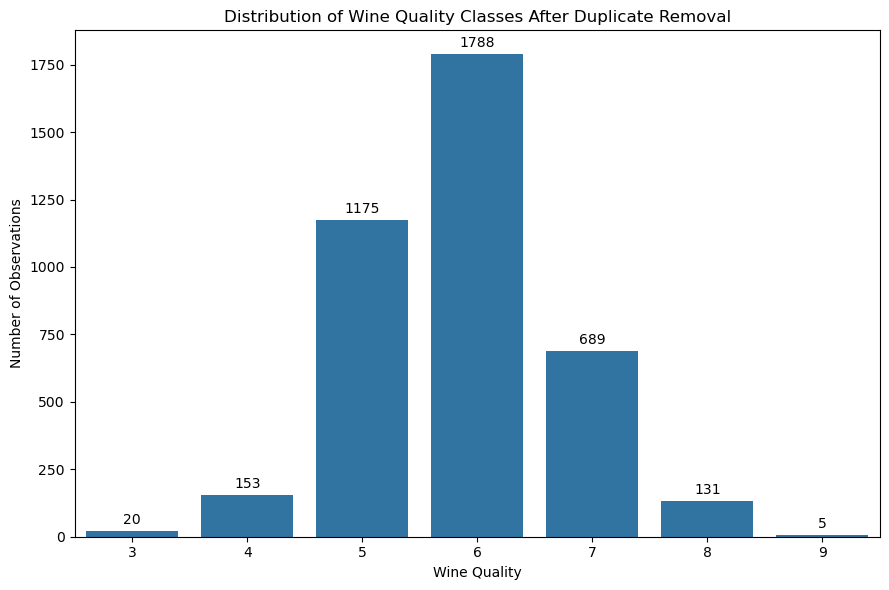

In [18]:
plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=df_unique,
    x="quality",
    order=sorted(df_unique["quality"].unique())
)

plt.title("Distribution of Wine Quality Classes After Duplicate Removal")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Observations")

# Add counts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

In [19]:
imbalance_ratio = (
    class_counts.max() /
    class_counts.min()
)

print(
    f"Imbalance ratio: {imbalance_ratio:.2f}"
)

Imbalance ratio: 357.60


Because the project is a multiclass pattern-recognition problem, and removing the rare classes simply because they are difficult to classify would alter the original problem.

I instead acknowledge the imbalance as a characteristic of the dataset.

## 6. Descriptive Statistics of Features

### 6.1 Mean

In [20]:
feature_means = X.mean()

print(feature_means)

fixed acidity             6.839346
volatile acidity          0.280538
citric acid               0.334332
residual sugar            5.914819
chlorides                 0.045905
free sulfur dioxide      34.889169
total sulfur dioxide    137.193512
density                   0.993790
pH                        3.195458
sulphates                 0.490351
alcohol                  10.589358
dtype: float64


### 6.2 Variance

In [21]:
feature_variances = X.var()

print(feature_variances)

fixed acidity              0.751446
volatile acidity           0.010699
citric acid                0.014993
residual sugar            23.635605
chlorides                  0.000534
free sulfur dioxide      296.184809
total sulfur dioxide    1860.116268
density                    0.000008
pH                         0.022966
sulphates                  0.012887
alcohol                    1.481275
dtype: float64


### 6.3 Standard Deviation

In [22]:
feature_std = X.std()

print(feature_std)

fixed acidity            0.866860
volatile acidity         0.103437
citric acid              0.122446
residual sugar           4.861646
chlorides                0.023103
free sulfur dioxide     17.210021
total sulfur dioxide    43.129065
density                  0.002905
pH                       0.151546
sulphates                0.113523
alcohol                  1.217076
dtype: float64


### 6.4 Covariance Matrix

In [23]:
covariance_matrix = X.cov()

print(covariance_matrix)

                      fixed acidity  volatile acidity  citric acid  \
fixed acidity              0.751446         -0.001723     0.031733   
volatile acidity          -0.001723          0.010699    -0.002067   
citric acid                0.031733         -0.002067     0.014993   
residual sugar             0.352405          0.049453     0.063261   
chlorides                  0.000481          0.000206     0.000375   
free sulfur dioxide       -0.871194         -0.182414     0.193200   
total sulfur dioxide       3.081614          0.456443     0.648741   
density                    0.000670          0.000018     0.000057   
pH                        -0.056656         -0.000736    -0.003396   
sulphates                 -0.001717         -0.000248     0.000687   
alcohol                   -0.116885          0.005894    -0.011403   

                      residual sugar  chlorides  free sulfur dioxide  \
fixed acidity               0.352405   0.000481            -0.871194   
volatile acidit

### Visualization

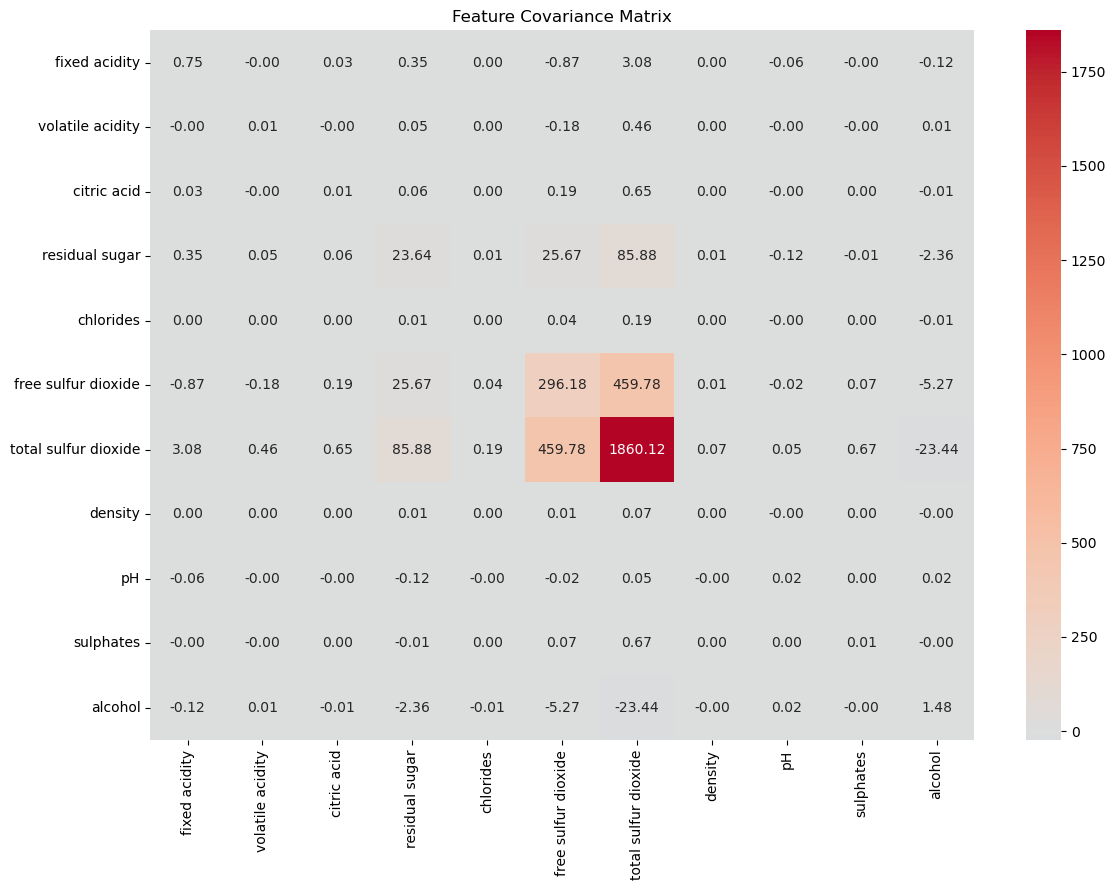

In [24]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    covariance_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Covariance Matrix")

plt.tight_layout()
plt.show()

### 6.5 Correlation Matrix

In [25]:
correlation_matrix = X.corr()

print(correlation_matrix)

                      fixed acidity  volatile acidity  citric acid  \
fixed acidity              1.000000         -0.019214     0.298959   
volatile acidity          -0.019214          1.000000    -0.163228   
citric acid                0.298959         -0.163228     1.000000   
residual sugar             0.083620          0.098340     0.106269   
chlorides                  0.024036          0.086287     0.132590   
free sulfur dioxide       -0.058396         -0.102471     0.091681   
total sulfur dioxide       0.082425          0.102315     0.122845   
density                    0.266091          0.060603     0.160076   
pH                        -0.431274         -0.046954    -0.183015   
sulphates                 -0.017453         -0.021150     0.049442   
alcohol                   -0.110788          0.046815    -0.076514   

                      residual sugar  chlorides  free sulfur dioxide  \
fixed acidity               0.083620   0.024036            -0.058396   
volatile acidit

### Visualization of the Correlation Matrix using a Heatmap

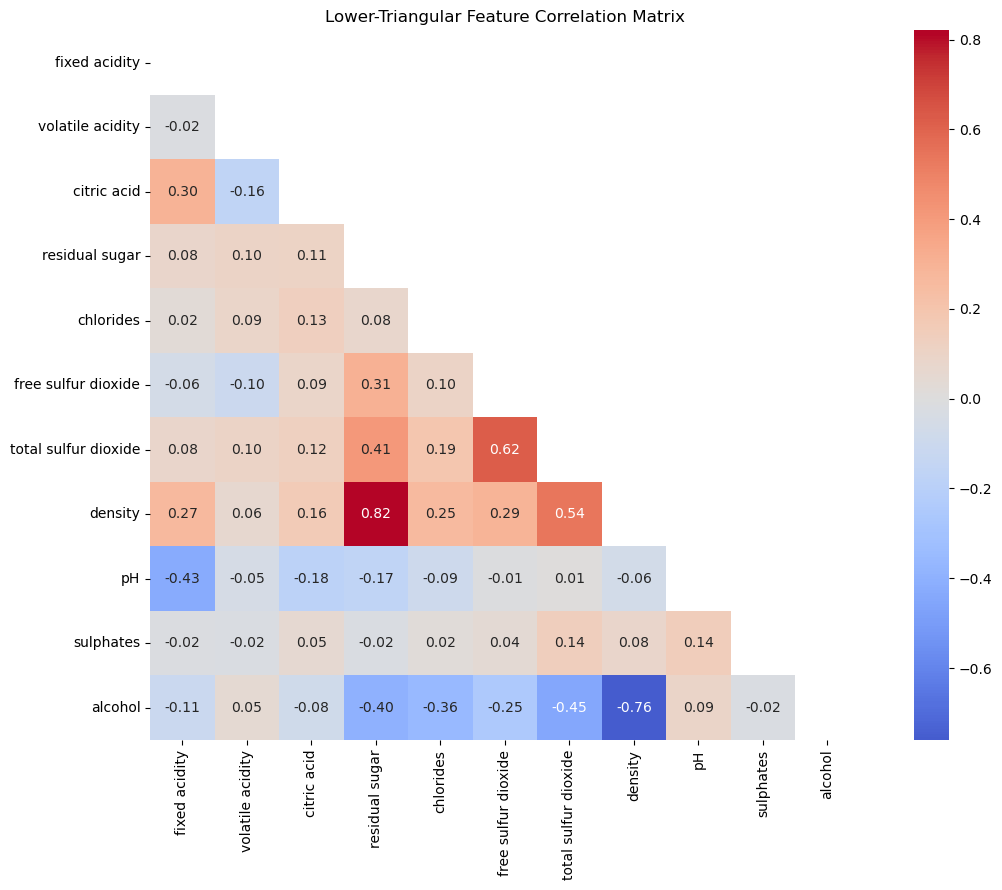

In [26]:
plt.figure(figsize=(12, 9))

# Create mask for the upper triangle
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Lower-Triangular Feature Correlation Matrix")

plt.tight_layout()
plt.show()

### 6.6 Feature Distributions

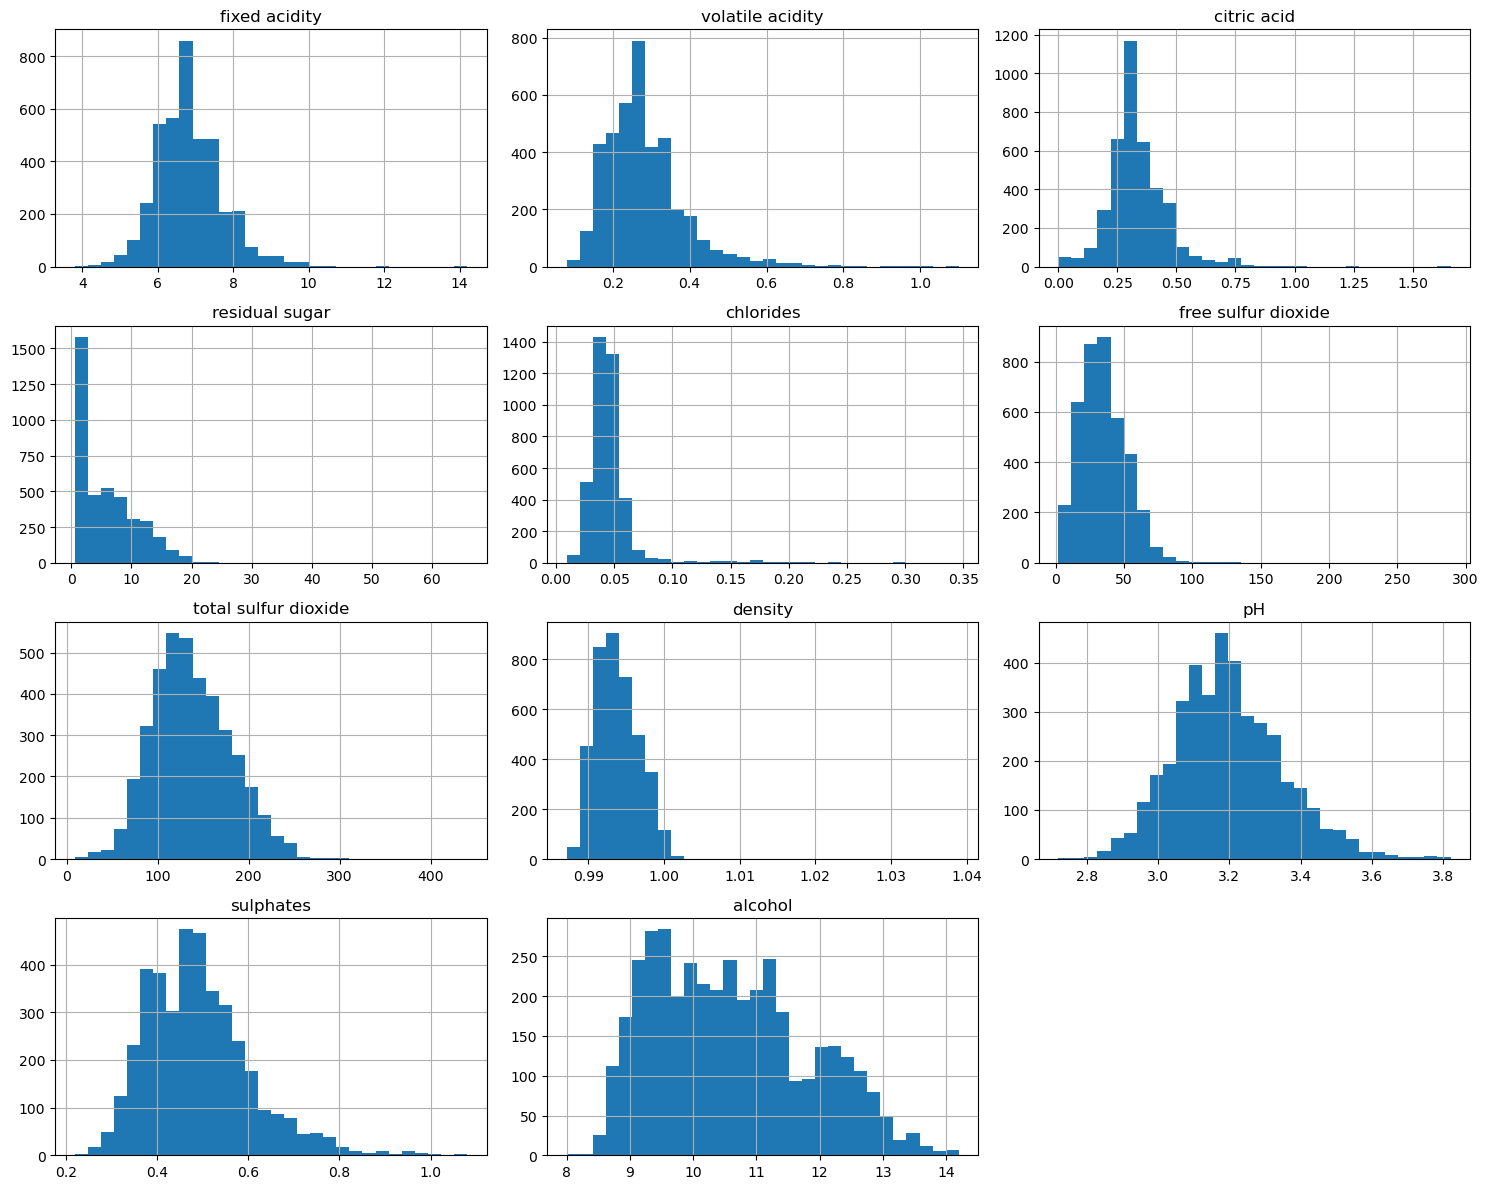

In [27]:
X.hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

### 6.7  Boxplots for each Feature

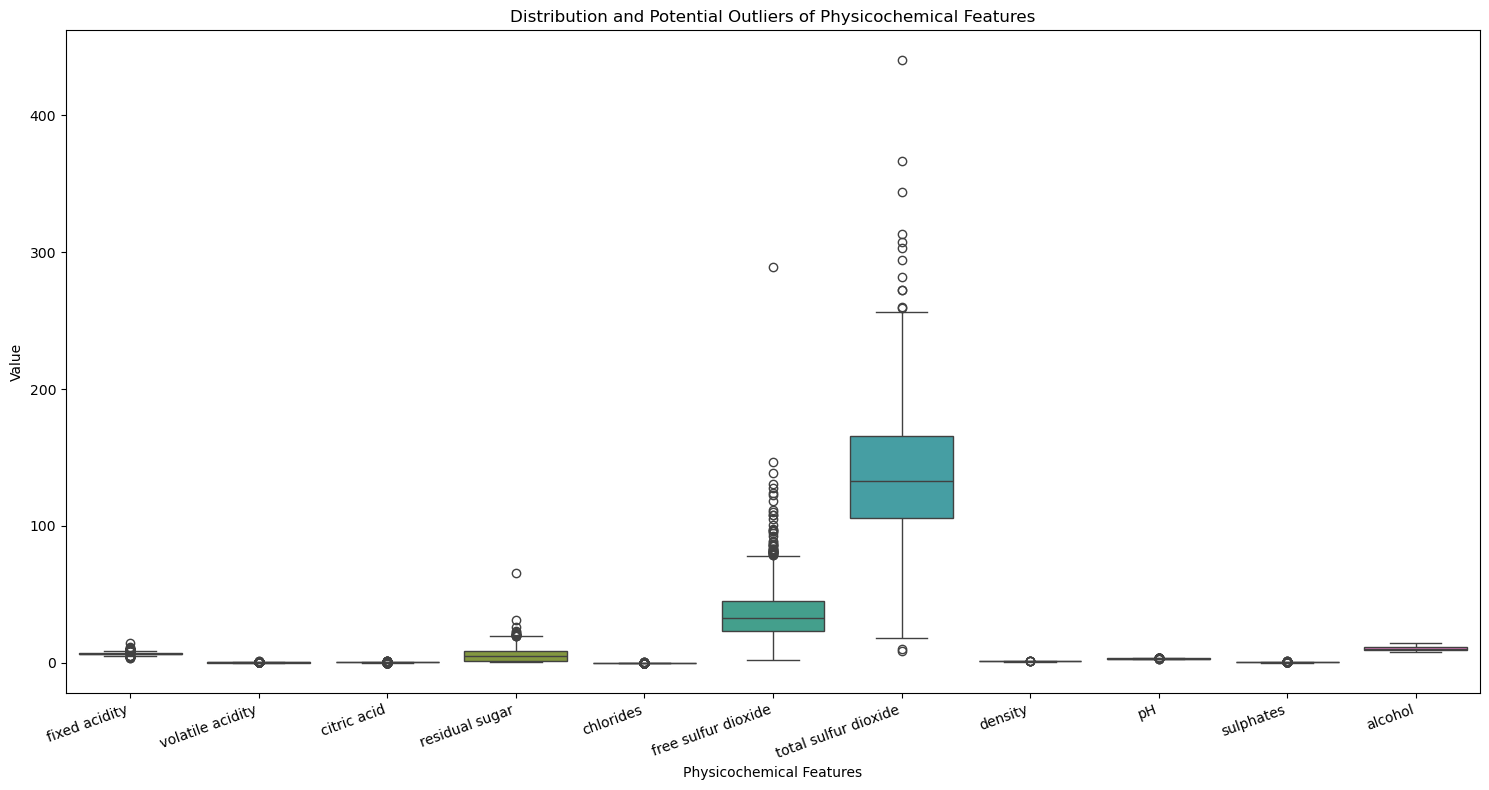

In [28]:
plt.figure(figsize=(15, 8))

sns.boxplot(
    data=X,
    orient="v"
)

plt.title("Distribution and Potential Outliers of Physicochemical Features")
plt.xlabel("Physicochemical Features")
plt.ylabel("Value")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

## 7. Data Preprocessing

### 7.1 Defining X and y

In [29]:


X = df_unique.drop(columns=["quality"])
y = df_unique["quality"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (3961, 11)
Target shape: (3961,)


### 7.2 Stratified Train/Test Split

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (3168, 11)
Testing set: (793, 11)


### Verifying the class distribution in the training and testing sets

In [31]:
train_distribution = (
    y_train.value_counts()
          .sort_index()
)

test_distribution = (
    y_test.value_counts()
         .sort_index()
)

split_distribution = pd.DataFrame({
    "Full Dataset": y.value_counts().sort_index(),
    "Training": train_distribution,
    "Testing": test_distribution
})

display(split_distribution)

,Full Dataset,Training,Testing
quality,,,
3,20,16,4
4,153,122,31
5,1175,940,235
6,1788,1430,358
7,689,551,138
8,131,105,26
9,5,4,1


### 7.3 Feature Standardization

In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (3168, 11)
Scaled testing shape: (793, 11)


### Verifying the Transformation

In [33]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

display(
    X_train_scaled_df.describe().T[
        ["mean", "std", "min", "max"]
    ]
)

,mean,std,min,max
fixed acidity,1.073216e-15,1.000158,-3.483537,8.407489
volatile acidity,1.794300e-16,1.000158,-1.933309,7.881336
citric acid,3.454027e-16,1.000158,-2.738298,10.836080
residual sugar,-9.868649e-17,1.000158,-1.113408,5.416013
chlorides,-1.099009e-16,1.000158,-1.561727,12.689280
free sulfur dioxide,-2.242875e-17,1.000158,-1.895929,14.621900
total sulfur dioxide,1.547584e-16,1.000158,-2.779284,7.037824
density,-3.899574e-14,1.000158,-2.370846,5.866446
pH,1.719724e-15,1.000158,-3.141843,4.122467
sulphates,-1.755050e-16,1.000158,-2.272826,5.153869


### Checking the test set 

In [34]:
X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

display(
    X_test_scaled_df.describe().T[
        ["mean", "std", "min", "max"]
    ]
)

,mean,std,min,max
fixed acidity,-0.042187,0.954129,-2.568842,3.605344
volatile acidity,-0.018455,0.976096,-1.933309,6.582339
citric acid,-0.021731,1.006210,-2.738298,5.439038
residual sugar,0.030137,1.114480,-1.092346,12.619439
chlorides,-0.005449,0.878790,-1.392576,8.375918
free sulfur dioxide,-0.015210,0.951431,-1.838376,4.809044
total sulfur dioxide,-0.032221,1.016102,-2.988653,3.850754
density,0.008901,1.149936,-2.331773,16.053834
pH,-0.009771,1.003928,-3.009765,3.924349
sulphates,0.009667,0.958681,-2.360199,4.105395


In [35]:
scaling_parameters = pd.DataFrame({
    "Feature": X_train.columns,
    "Training_Mean": scaler.mean_,
    "Training_Scale": scaler.scale_
})

display(scaling_parameters)

,Feature,Training_Mean,Training_Scale
0,fixed acidity,6.846733,0.874609
1,volatile acidity,0.280922,0.103926
2,citric acid,0.334864,0.122289
3,residual sugar,5.886174,4.747741
4,chlorides,0.045931,0.023647
5,free sulfur dioxide,34.942077,17.375165
6,total sulfur dioxide,137.470802,42.986182
7,density,0.993785,0.002815
8,pH,3.195754,0.151425
9,sulphates,0.490129,0.114452


## 8. Gaussian Bayesian Classifier

### 8.1 Model Implementation

In [36]:
class GaussianBayesianClassifier:
    
    def __init__(self):
        self.classes_ = None
        self.priors_ = {}
        self.means_ = {}
        self.covariances_ = {}

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)

        self.classes_ = np.unique(y)

        for cls in self.classes_:

            X_class = X[y == cls]

            if len(X_class) < 2:
                raise ValueError(
                    f"Class {cls} has fewer than 2 observations."
                )

            # Prior probability P(C = cls)
            self.priors_[cls] = (
                len(X_class) / len(X)
            )

            # Mean vector μ_cls
            self.means_[cls] = np.mean(
                X_class,
                axis=0
            )

            # Full covariance matrix Σ_cls
            self.covariances_[cls] = np.cov(
                X_class,
                rowvar=False
            )

        return self

    def _log_gaussian_density(
        self,
        X,
        mean,
        covariance
    ):

        n_features = X.shape[1]

        # Small regularization for numerical stability
        covariance = covariance + (
            1e-6 * np.eye(n_features)
        )

        sign, log_det = np.linalg.slogdet(
            covariance
        )

        if sign <= 0:
            raise ValueError(
                "Covariance matrix is not positive definite."
            )

        covariance_inv = np.linalg.inv(
            covariance
        )

        diff = X - mean

        exponent = -0.5 * np.sum(
            (diff @ covariance_inv) * diff,
            axis=1
        )

        constant = -0.5 * (
            n_features * np.log(2 * np.pi)
            + log_det
        )

        return constant + exponent

    def predict_proba(self, X):

        X = np.asarray(X)

        log_posteriors = []

        for cls in self.classes_:

            log_likelihood = (
                self._log_gaussian_density(
                    X,
                    self.means_[cls],
                    self.covariances_[cls]
                )
            )

            log_prior = np.log(
                self.priors_[cls]
            )

            log_posteriors.append(
                log_likelihood + log_prior
            )

        log_posteriors = np.column_stack(
            log_posteriors
        )

        # Log-sum-exp normalization
        max_log = np.max(
            log_posteriors,
            axis=1,
            keepdims=True
        )

        probabilities = np.exp(
            log_posteriors - max_log
        )

        probabilities /= np.sum(
            probabilities,
            axis=1,
            keepdims=True
        )

        return probabilities

    def predict(self, X):

        probabilities = self.predict_proba(X)

        indices = np.argmax(
            probabilities,
            axis=1
        )

        return self.classes_[indices]

### 8.2 Model Training

In [37]:
bayesian_model = GaussianBayesianClassifier()

bayesian_model.fit(
    X_train_scaled,
    y_train
)

### 8.3 Model Parameter Inspection

In [38]:
print("Classes:")
print(bayesian_model.classes_)

print("\nClass Priors:")
print(bayesian_model.priors_)

Classes:
[3 4 5 6 7 8 9]

Class Priors:
{3: 0.005050505050505051, 4: 0.03851010101010101, 5: 0.2967171717171717, 6: 0.4513888888888889, 7: 0.17392676767676768, 8: 0.03314393939393939, 9: 0.0012626262626262627}


In [39]:
print("\nClass Means:")

for cls in bayesian_model.classes_:
    print(f"\nClass {cls}:")
    print(bayesian_model.means_[cls])


Class Means:

Class 3:
[ 0.96130601  0.45119254 -0.06022009  0.14311033 -0.02086361  1.07886304
  0.68694628  0.39578647 -0.05863896 -0.26324942 -0.17860142]

Class 4:
[ 0.3392483   1.03892564 -0.27705354 -0.28954799  0.21540245 -0.61961125
 -0.20382795  0.18706491 -0.01256039 -0.07346406 -0.35094213]

Class 5:
[ 0.09490078  0.21254404  0.01963942  0.2089115   0.27302573  0.03808001
  0.27479009  0.45332652 -0.1774568  -0.05922444 -0.60502793]

Class 6:
[-0.02272993 -0.18179941  0.03742187  0.00998205 -0.0261459   0.03714126
 -0.00242795 -0.03119624  0.00891843  0.00406272  0.05675743]

Class 7:
[-0.15365921 -0.14796301 -0.07153627 -0.27751551 -0.36078294 -0.06492614
 -0.36697361 -0.59211383  0.22795282  0.12318926  0.74940984]

Class 8:
[-0.30497389  0.07314886  0.00149933 -0.2209538  -0.41592782  0.06582023
 -0.34937787 -0.77812364  0.26452064 -0.04689752  1.09999295]

Class 9:
[ 0.80409293  0.01518655  0.51219341 -0.37621562 -0.68425433 -0.42831692
 -0.51692894 -0.67827614  0.78748

### 8.4 Model Prediction

In [40]:

y_pred_bayesian = bayesian_model.predict(X_test_scaled)

print("Number of predictions:", len(y_pred_bayesian))
print("Number of test observations:", len(y_test))

Number of predictions: 793
Number of test observations: 793


### 8.5 Model Evaluation

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

bayesian_results = {
    "Accuracy": accuracy_score(
        y_test,
        y_pred_bayesian
    ),

    "Precision_Macro": precision_score(
        y_test,
        y_pred_bayesian,
        average="macro",
        zero_division=0
    ),

    "Recall_Macro": recall_score(
        y_test,
        y_pred_bayesian,
        average="macro",
        zero_division=0
    ),

    "F1_Macro": f1_score(
        y_test,
        y_pred_bayesian,
        average="macro",
        zero_division=0
    ),

    "Precision_Weighted": precision_score(
        y_test,
        y_pred_bayesian,
        average="weighted",
        zero_division=0
    ),

    "Recall_Weighted": recall_score(
        y_test,
        y_pred_bayesian,
        average="weighted",
        zero_division=0
    ),

    "F1_Weighted": f1_score(
        y_test,
        y_pred_bayesian,
        average="weighted",
        zero_division=0
    )
}

bayesian_results

{'Accuracy': 0.47540983606557374,
 'Precision_Macro': 0.3134661635615391,
 'Recall_Macro': 0.29253260717710233,
 'F1_Macro': 0.2908770646058904,
 'Precision_Weighted': 0.48199112861142307,
 'Recall_Weighted': 0.47540983606557374,
 'F1_Weighted': 0.4695429283586556}

In [42]:
print("Classification Report")
print("-" * 40)

print(
    classification_report(
        y_test,
        y_pred_bayesian,
        zero_division=0
    )
)

Classification Report
----------------------------------------
              precision    recall  f1-score   support

           3       0.33      0.25      0.29         4
           4       0.28      0.16      0.20        31
           5       0.57      0.49      0.53       235
           6       0.51      0.46      0.49       358
           7       0.37      0.64      0.47       138
           8       0.12      0.04      0.06        26
           9       0.00      0.00      0.00         1

    accuracy                           0.48       793
   macro avg       0.31      0.29      0.29       793
weighted avg       0.48      0.48      0.47       793



### 8.6 Confusion Matrix for Bayesian Classifier

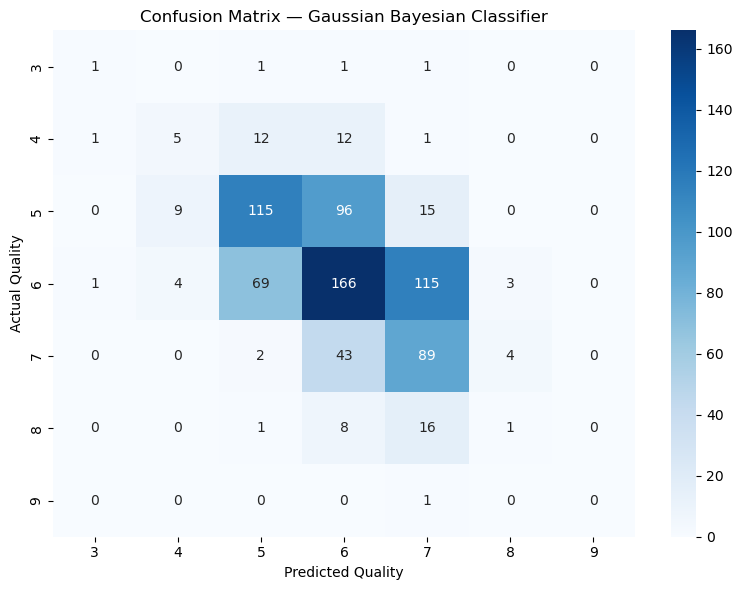

In [43]:


cm_bayesian = confusion_matrix(
    y_test,
    y_pred_bayesian,
    labels=bayesian_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_bayesian,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=bayesian_model.classes_,
    yticklabels=bayesian_model.classes_
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("Confusion Matrix — Gaussian Bayesian Classifier")

plt.tight_layout()
plt.show()

## 9. k-Nearest Heighbour Classifier

### 9.1 Model Implementation

In [44]:
from sklearn.neighbors import KNeighborsClassifier

### 9.2  Model Training - Effect of k

In [45]:
k_values = [1, 3, 5, 7, 9]

knn_models = {}

for k in k_values:

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean"
    )

    model.fit(X_train_scaled, y_train)

    knn_models[k] = model

### 9.3 Model Prediction

In [46]:

knn_predictions = {}

for k, model in knn_models.items():

    knn_predictions[k] = model.predict(
        X_test_scaled
    )

### 9.4 Model Evaluation Accross k

In [47]:

knn_results = []

for k in k_values:

    y_pred = knn_predictions[k]

    knn_results.append({
        "k": k,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision_Macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall_Macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Precision_Weighted": precision_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall_Weighted": recall_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1_Weighted": f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )
    })

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df.round(4))

,k,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted
0,1,0.4779,0.2598,0.2535,0.2558,0.4728,0.4779,0.4751
1,3,0.4830,0.2813,0.2501,0.2476,0.4796,0.4830,0.4761
2,5,0.4893,0.3041,0.2349,0.2432,0.4758,0.4893,0.4739
3,7,0.4994,0.3231,0.2349,0.2438,0.4872,0.4994,0.4822
4,9,0.5170,0.2994,0.2345,0.2415,0.4946,0.5170,0.4955


### 9.5 Effect of k

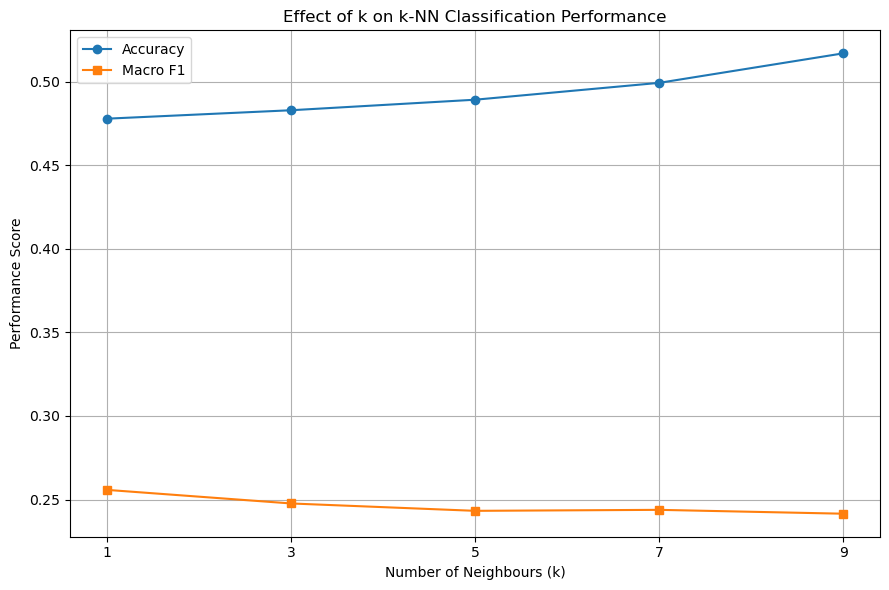

In [48]:

plt.figure(figsize=(9, 6))

plt.plot(
    knn_results_df["k"],
    knn_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_results_df["k"],
    knn_results_df["F1_Macro"],
    marker="s",
    label="Macro F1"
)

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Performance Score")
plt.title("Effect of k on k-NN Classification Performance")

plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 9.6 Distance Metric Comparison

In [49]:

distance_metrics = ["euclidean", "manhattan"]

distance_models = {}
distance_predictions = {}
distance_results = []

for metric in distance_metrics:

    model = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    y_pred = model.predict(
        X_test_scaled
    )

    distance_models[metric] = model
    distance_predictions[metric] = y_pred

    distance_results.append({
        "Distance": metric,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision_Macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall_Macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Precision_Weighted": precision_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall_Weighted": recall_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1_Weighted": f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )
    })

distance_results_df = pd.DataFrame(
    distance_results
)

display(distance_results_df.round(4))

,Distance,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted
0,euclidean,0.4893,0.3041,0.2349,0.2432,0.4758,0.4893,0.4739
1,manhattan,0.5170,0.3316,0.2415,0.2495,0.5027,0.5170,0.4977


### 9.7 Distance Metric Confusion Matrices

### 9.7.1 Euclidean Distance — Confusion Matrix

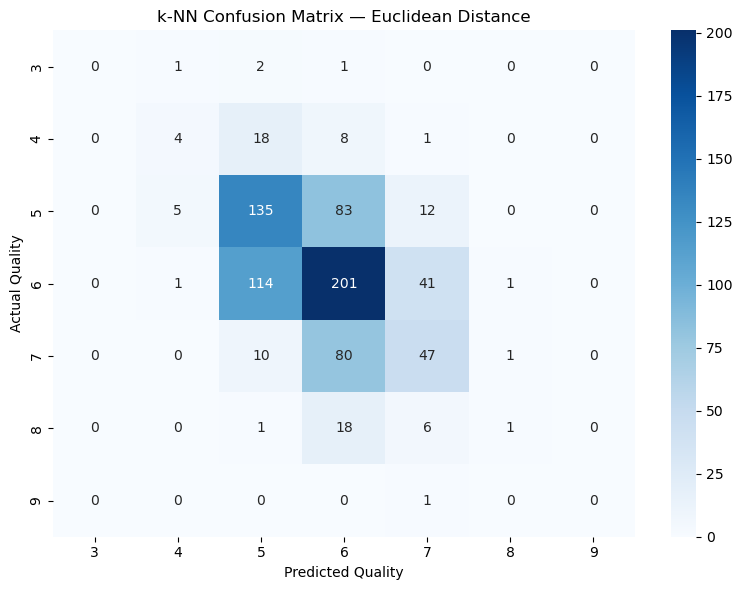

In [50]:
classes = sorted(y_test.unique())



cm_euclidean = confusion_matrix(
    y_test,
    distance_predictions["euclidean"],
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_euclidean,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title(
    "k-NN Confusion Matrix — Euclidean Distance"
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")

plt.tight_layout()
plt.show()

### 9.7.2 Manhattan Distance — Confusion Matrix

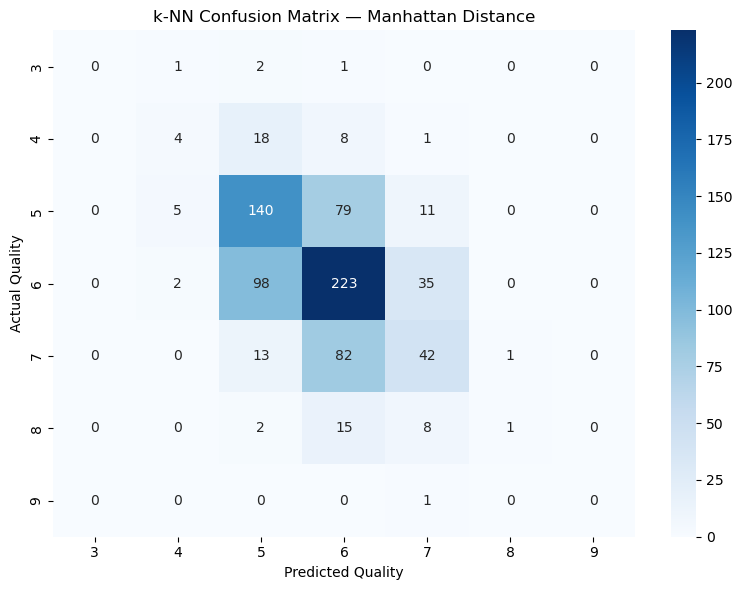

In [51]:


cm_manhattan = confusion_matrix(
    y_test,
    distance_predictions["manhattan"],
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_manhattan,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title(
    "k-NN Confusion Matrix — Manhattan Distance"
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")

plt.tight_layout()
plt.show()

## 10. Overall Model Comparison

In [52]:
model_comparison = pd.DataFrame([
    {
        "Model": "Gaussian Bayesian",
        "Accuracy": bayesian_results["Accuracy"],
        "Precision_Macro": bayesian_results["Precision_Macro"],
        "Recall_Macro": bayesian_results["Recall_Macro"],
        "F1_Macro": bayesian_results["F1_Macro"],
        "Precision_Weighted": bayesian_results["Precision_Weighted"],
        "Recall_Weighted": bayesian_results["Recall_Weighted"],
        "F1_Weighted": bayesian_results["F1_Weighted"]
    }
])

# Add all Euclidean k-NN models
for _, row in knn_results_df.iterrows():

    model_comparison.loc[len(model_comparison)] = {
        "Model": f"k-NN (Euclidean, k={int(row['k'])})",
        "Accuracy": row["Accuracy"],
        "Precision_Macro": row["Precision_Macro"],
        "Recall_Macro": row["Recall_Macro"],
        "F1_Macro": row["F1_Macro"],
        "Precision_Weighted": row["Precision_Weighted"],
        "Recall_Weighted": row["Recall_Weighted"],
        "F1_Weighted": row["F1_Weighted"]
    }

# Add Manhattan k-NN model at k=5
manhattan_row = distance_results_df[
    distance_results_df["Distance"] == "manhattan"
].iloc[0]

model_comparison.loc[len(model_comparison)] = {
    "Model": "k-NN (Manhattan, k=5)",
    "Accuracy": manhattan_row["Accuracy"],
    "Precision_Macro": manhattan_row["Precision_Macro"],
    "Recall_Macro": manhattan_row["Recall_Macro"],
    "F1_Macro": manhattan_row["F1_Macro"],
    "Precision_Weighted": manhattan_row["Precision_Weighted"],
    "Recall_Weighted": manhattan_row["Recall_Weighted"],
    "F1_Weighted": manhattan_row["F1_Weighted"]
}

display(model_comparison.round(4))

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted
0,Gaussian Bayesian,0.4754,0.3135,0.2925,0.2909,0.4820,0.4754,0.4695
1,"k-NN (Euclidean, k=1)",0.4779,0.2598,0.2535,0.2558,0.4728,0.4779,0.4751
2,"k-NN (Euclidean, k=3)",0.4830,0.2813,0.2501,0.2476,0.4796,0.4830,0.4761
3,"k-NN (Euclidean, k=5)",0.4893,0.3041,0.2349,0.2432,0.4758,0.4893,0.4739
4,"k-NN (Euclidean, k=7)",0.4994,0.3231,0.2349,0.2438,0.4872,0.4994,0.4822
5,"k-NN (Euclidean, k=9)",0.5170,0.2994,0.2345,0.2415,0.4946,0.5170,0.4955
6,"k-NN (Manhattan, k=5)",0.5170,0.3316,0.2415,0.2495,0.5027,0.5170,0.4977


### 10.1 Accuracy Graph

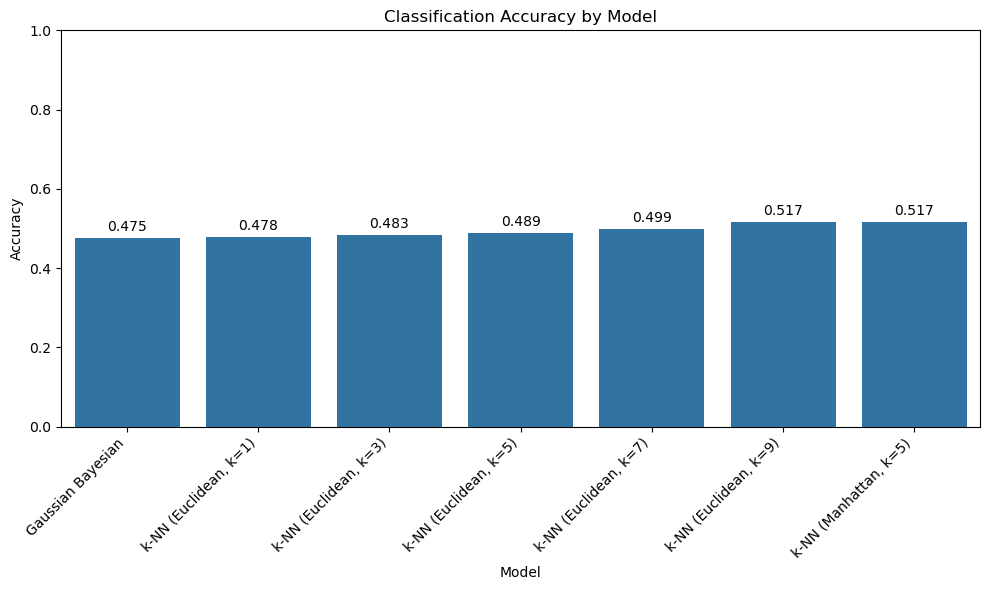

In [53]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

# Add accuracy values on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("Classification Accuracy by Model")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 10.2 Macro F1-score

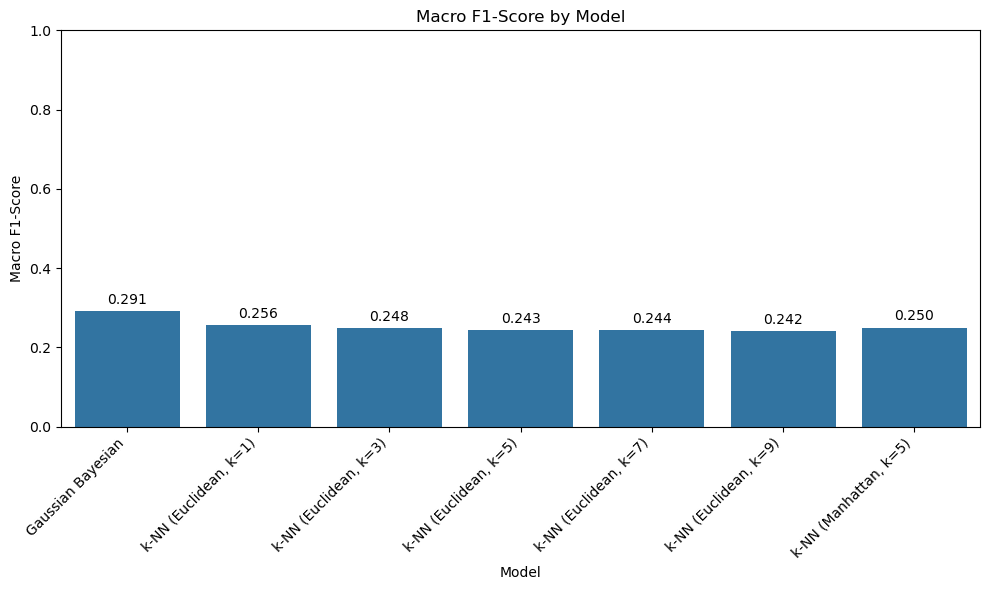

In [54]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=model_comparison,
    x="Model",
    y="F1_Macro"
)

# Add Macro F1 values on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("Macro F1-Score by Model")
plt.xlabel("Model")
plt.ylabel("Macro F1-Score")
plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 10.3 Euclidean vs Manhattan 

In [55]:
distance_comparison = pd.DataFrame(distance_results)

display(
    distance_comparison.round(4)
)

,Distance,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted
0,euclidean,0.4893,0.3041,0.2349,0.2432,0.4758,0.4893,0.4739
1,manhattan,0.5170,0.3316,0.2415,0.2495,0.5027,0.5170,0.4977


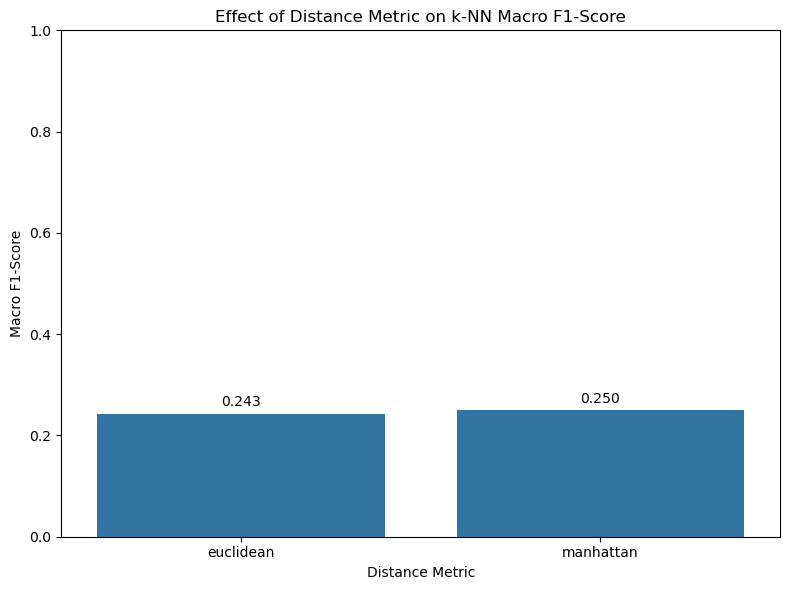

In [56]:
plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=distance_comparison,
    x="Distance",
    y="F1_Macro"
)

# Add actual Macro F1 values on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("Effect of Distance Metric on k-NN Macro F1-Score")
plt.xlabel("Distance Metric")
plt.ylabel("Macro F1-Score")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [57]:
display(model_comparison.round(4))

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted
0,Gaussian Bayesian,0.4754,0.3135,0.2925,0.2909,0.4820,0.4754,0.4695
1,"k-NN (Euclidean, k=1)",0.4779,0.2598,0.2535,0.2558,0.4728,0.4779,0.4751
2,"k-NN (Euclidean, k=3)",0.4830,0.2813,0.2501,0.2476,0.4796,0.4830,0.4761
3,"k-NN (Euclidean, k=5)",0.4893,0.3041,0.2349,0.2432,0.4758,0.4893,0.4739
4,"k-NN (Euclidean, k=7)",0.4994,0.3231,0.2349,0.2438,0.4872,0.4994,0.4822
5,"k-NN (Euclidean, k=9)",0.5170,0.2994,0.2345,0.2415,0.4946,0.5170,0.4955
6,"k-NN (Manhattan, k=5)",0.5170,0.3316,0.2415,0.2495,0.5027,0.5170,0.4977


In [58]:
display(distance_comparison.round(4))

,Distance,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted
0,euclidean,0.4893,0.3041,0.2349,0.2432,0.4758,0.4893,0.4739
1,manhattan,0.5170,0.3316,0.2415,0.2495,0.5027,0.5170,0.4977
